## Bimodal Switches

Like seen in [Drijfhout et al., 2015].

In [4]:
import numpy as np
import matplotlib.pyplot as plt

central_time = 50
interval_length = -13
duration = None
magnitude = -1.0

def make_shift(
        time_arr,
        time_offset= 0,
):

    if interval_length == 0:    # raise error as otherwise infinite loop occurs
        raise ValueError("Interval length cannot be zero.")

    t_shift = central_time + time_offset
    shift_effect = np.zeros_like(time_arr)
    j = 0

    if interval_length > 0:
        # Forward iteration
        while (central_time + interval_length * j) < len(time_arr):
            start = int(central_time + interval_length * j)
            end = int(central_time + interval_length * (j + 1))
            shift_effect[start:end] = magnitude
            j += 2
    else:
        # Backward iteration
        while (central_time + interval_length * j) >= 0:
            start = int(central_time + interval_length * j)
            end = int(central_time + interval_length * (j + 1))
            shift_effect[end:start] = magnitude
            j += 2

    return shift_effect, t_shift 


In [162]:
import numpy as np
import matplotlib.pyplot as plt

central_time = 50
interval_length = -3
duration = 13
magnitude = 1

def make_shift(
        time_arr,
        time_offset= 0,
):

    if interval_length == 0:    # raise error as otherwise infinite loop occurs
        raise ValueError("Interval length cannot be zero.")

    t_shift = central_time + time_offset
    shift_effect = np.zeros_like(time_arr)
    final_time = len(time_arr)
    start_time = 0

    # bootstrap loop
    start = int(central_time)
    j = 0
    
    if duration is not None:
        if interval_length > 0:
            final_time = central_time + duration - 1
        else:
            start_time = central_time - duration

    while not(start > final_time) and not(start <= start_time):
        #print(f"{j=}; {start=}")
        if interval_length > 0:         # Forward
            #print(abs(magnitude * (j % 2 - 1)))
            shift_effect[start+1:] = magnitude * abs(j % 2 - 1)
        else:                           # Backward
            #print(abs(magnitude * (j % 2 - 1)))
            shift_effect[:start] = magnitude * abs(j % 2 - 1)

        j += 1
        start = int(central_time + interval_length * j)

    return shift_effect, t_shift 


Shift Effect: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 0. 1. 1. 1. 0. 0. 0. 1.
 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0.]
Time of Shift: 50


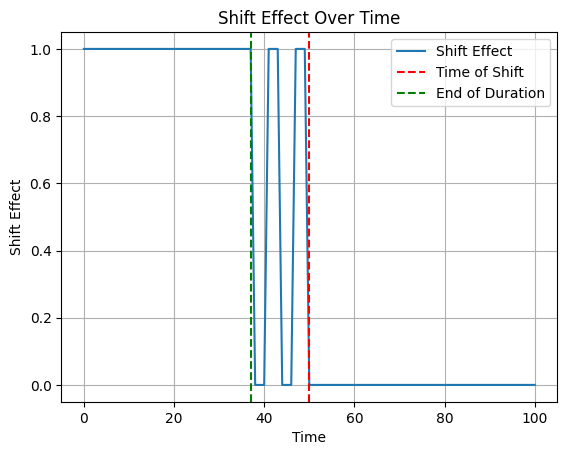

In [163]:
time_arr = np.linspace(0, 100, 101)

shift_effect, t_shift = make_shift(
    time_arr,
    time_offset=0)

print("Shift Effect:", shift_effect)
print("Time of Shift:", t_shift)

plt.plot(time_arr, shift_effect, label='Shift Effect')
plt.axvline(x=t_shift, color='r', linestyle='--', label='Time of Shift')
plt.axvline(x=central_time+(duration*np.sign(interval_length)), color='g', linestyle='--', label='End of Duration' if duration is not None else '')
plt.title("Shift Effect Over Time")
plt.xlabel("Time")
plt.ylabel("Shift Effect")
plt.legend()
plt.grid()
plt.show()


## Test out in PONDS

In [5]:
from ponds import PONDS, SIGMOID, WhiteNoise, BIMODAL, ELLIPSIS
import matplotlib.pyplot as plt

# initialize PONDS object
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
)

# add background with white noise
pd.add_background(
    background_method=WhiteNoise(
        magnitude=0.05,
        background_seed=42,
    )
)

# add random shift
pd.add_shift(
    shape_method=ELLIPSIS(shape_seed=4),
    shift_method=BIMODAL(
        central_time=50,
        magnitude=4.5,
        interval_length=3,
        duration=14,
    )
)


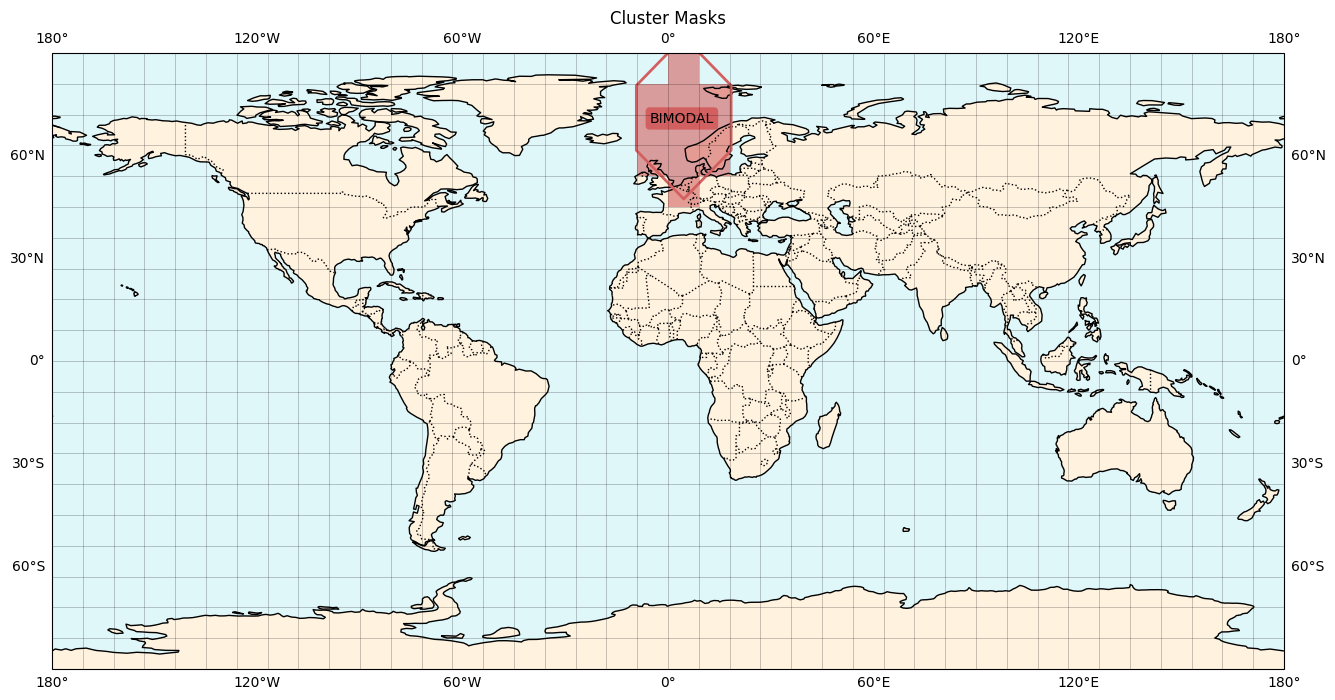

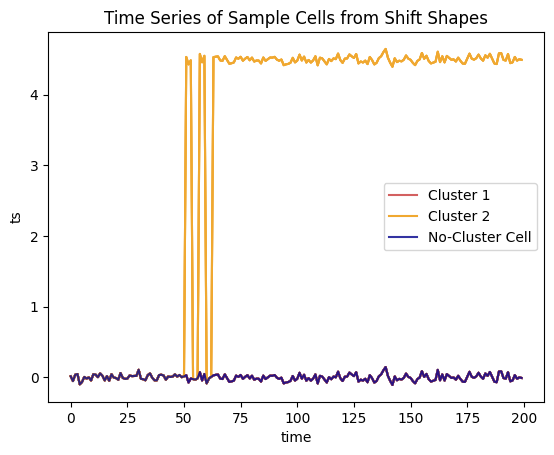

In [8]:
# look at the generated synthetic data
pd.worldmap(
    show_cells=True,
    shift_type=True,
    )
plt.show()

# plot time series of sample cells
lat1, lon1 = 8, 28  # cell of cluster in indian ocean
lat2, lon2 = 17, 20  # cell of cluster in northern europe
for i in range(3):
    pd.data.ts.isel(lat=0, lon=0 + i).plot.line(x="time", color="darkblue", alpha=0.8)
    pd.data.ts.isel(lat=lat1, lon=lon1 + i).plot.line(x="time", color="#d36060")
    pd.data.ts.isel(lat=lat2, lon=lon2 + i).plot.line(x="time", color="#f0a830")
pd.data.ts.isel(lat=lat1, lon=lon1).plot.line(
    x="time", color="#d36060", label="Cluster 1"
)
pd.data.ts.isel(lat=lat2, lon=lon2).plot.line(
    x="time", color="#f0a830", label="Cluster 2"
)
pd.data.ts.isel(lat=0, lon=0).plot.line(
    x="time", color="darkblue", alpha=0.8, label="No-Cluster Cell"
)

plt.legend()
plt.title("Time Series of Sample Cells from Shift Shapes")
plt.show()